# 📘 Notebook 07: Optimisers, SGD, Momentum, RMSprop and Adam

### Course: *From Defaults to Decisions: Hyperparameters, Explained by Experiment*
**Instructor:** Ioannis Tsioulis

---

> 💡 **This notebook is already run.** Every number and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** About **fifteen minutes** on an ordinary processor. Each optimiser is compared at **its own** best learning rate, found by a small sweep, because comparing them at one shared rate is unfair. On large models the ranking can differ; well-tuned SGD with momentum still wins some image benchmarks.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain plain **SGD**, **momentum**, **RMSprop** and **Adam** in one sentence each
- Watch them on a narrow valley, where their differences are visible
- Compare them **fairly**, each at its own tuned learning rate
- Explain why Adam is a good default and when SGD with momentum is still used
- Explain **AdamW** and why weight decay differs between Adam and AdamW

> **Prerequisites:** [Notebook 03: The Learning Rate](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-defaults-to-decisions/03_learning_rate.ipynb).
>
> 🔭 **Why this notebook matters:** the optimiser decides how the gradient is turned into a step. A good optimiser can make the same network train several times faster and be much less sensitive to the learning rate.

## 1. The papers

> 📄 Momentum: B. T. Polyak, *Some methods of speeding up the convergence of iteration methods*, 1964; I. Sutskever et al., [*On the importance of initialization and momentum in deep learning*](https://proceedings.mlr.press/v28/sutskever13.html), ICML 2013.
>
> 📄 RMSprop: G. Hinton, lecture 6e of the Coursera course *Neural Networks for Machine Learning*, 2012 (never published as a paper).
>
> 📄 Adam: D. P. Kingma and J. Ba, [*Adam: A Method for Stochastic Optimization*](https://arxiv.org/abs/1412.6980), ICLR 2015.
>
> 📄 AdamW: I. Loshchilov and F. Hutter, [*Decoupled Weight Decay Regularization*](https://arxiv.org/abs/1711.05101), ICLR 2019.

### Intuition first
- **SGD:** step against the gradient. Simple, but slow in narrow valleys, where it zig-zags across instead of moving along.
- **Momentum:** keep a running **velocity**; each step adds the gradient to the velocity, like a ball rolling downhill. Zig-zags cancel out, consistent directions build up speed.
- **RMSprop:** divide each weight's step by the recent **size** of its gradients, so steep directions get smaller steps and flat ones larger.
- **Adam:** momentum **and** RMSprop together, with a correction for the first steps. It works reasonably well with little tuning, which is why it is the common default.

In [1]:
# Shared setup: the same data, model builder and training loop in every notebook of this course.
import warnings
warnings.filterwarnings("ignore")

import gzip, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.precision", 3)

BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
def read_idx(name, header):
    return np.frombuffer(gzip.decompress(urllib.request.urlopen(BASE + name).read()), dtype=np.uint8, offset=header)

images = torch.tensor(read_idx("train-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
labels = torch.tensor(read_idx("train-labels-idx1-ubyte.gz", 8), dtype=torch.long)
X_test = torch.tensor(read_idx("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
y_test = torch.tensor(read_idx("t10k-labels-idx1-ubyte.gz", 8), dtype=torch.long)
mean, std = images.mean(), images.std()
images, X_test = (images - mean) / std, (X_test - mean) / std

order = torch.randperm(len(images), generator=torch.Generator().manual_seed(0))
X_train, y_train = images[order[:10000]], labels[order[:10000]]       # 10,000 images to learn from
X_val, y_val = images[order[10000:15000]], labels[order[10000:15000]] # 5,000 to choose hyperparameters
print(f"train {len(X_train):,}   validation {len(X_val):,}   test {len(X_test):,}")

def make_mlp(hidden=(128,), activation=nn.ReLU, dropout=0.0, batchnorm=False):
    layers, width = [], 784
    for h in hidden:
        layers.append(nn.Linear(width, h))
        if batchnorm:
            layers.append(nn.BatchNorm1d(h))
        layers.append(activation())
        if dropout:
            layers.append(nn.Dropout(dropout))
        width = h
    layers.append(nn.Linear(width, 10))
    return nn.Sequential(*layers)

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

def fit(model, epochs=20, lr=1e-3, batch=128, optimizer="adam", weight_decay=0.0, scheduler=None, seed=0, X=None, y=None):
    """Train and return a history with one row per epoch."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    torch.manual_seed(seed)
    opts = {"sgd": lambda p: torch.optim.SGD(p, lr=lr, weight_decay=weight_decay),
            "momentum": lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9, weight_decay=weight_decay),
            "rmsprop": lambda p: torch.optim.RMSprop(p, lr=lr, weight_decay=weight_decay),
            "adam": lambda p: torch.optim.Adam(p, lr=lr, weight_decay=weight_decay),
            "adamw": lambda p: torch.optim.AdamW(p, lr=lr, weight_decay=weight_decay)}
    opt = opts[optimizer](model.parameters())
    steps_per_epoch = (len(X) + batch - 1) // batch
    sched = scheduler(opt, epochs * steps_per_epoch) if scheduler else None
    rows, start = [], time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(X))
        total = 0.0
        for i in range(0, len(X), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            if sched:
                sched.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val_loss = F.cross_entropy(model(X_val), y_val).item()
        rows.append({"epoch": epoch, "train loss": total / len(X), "val loss": val_loss,
                     "train acc": accuracy(model, X, y), "val acc": accuracy(model, X_val, y_val)})
    history = pd.DataFrame(rows).set_index("epoch")
    history.attrs["seconds"] = time.time() - start
    return history

train 10,000   validation 5,000   test 10,000


## 2. A narrow valley

The function $f(x, y) = 0.05\,x^2 + 2\,y^2$ is a long, narrow valley: steep across ($y$), gentle along ($x$). Each optimiser starts at $(-9, 2)$ and takes 60 steps.

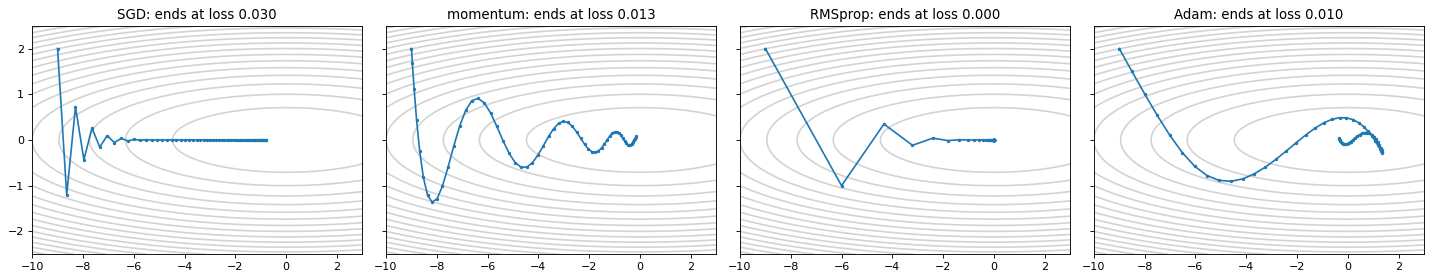

In [2]:
def valley(p):
    return 0.05 * p[0] ** 2 + 2 * p[1] ** 2

paths = {}
for name, make, lr in [("SGD", lambda p, lr: torch.optim.SGD([p], lr=lr), 0.4),
                       ("momentum", lambda p, lr: torch.optim.SGD([p], lr=lr, momentum=0.9), 0.04),
                       ("RMSprop", lambda p, lr: torch.optim.RMSprop([p], lr=lr), 0.3),
                       ("Adam", lambda p, lr: torch.optim.Adam([p], lr=lr), 0.5)]:
    p = torch.tensor([-9.0, 2.0], requires_grad=True)
    opt = make(p, lr)
    path = [p.detach().clone()]
    for _ in range(60):
        opt.zero_grad(); valley(p).backward(); opt.step()
        path.append(p.detach().clone())
    paths[name] = torch.stack(path).numpy()

gx, gy = np.meshgrid(np.linspace(-10, 3, 200), np.linspace(-2.5, 2.5, 200))
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for ax, (name, path) in zip(axes, paths.items()):
    ax.contour(gx, gy, 0.05 * gx ** 2 + 2 * gy ** 2, levels=20, colors="lightgrey")
    ax.plot(path[:, 0], path[:, 1], marker="o", ms=2)
    ax.set_title(f"{name}: ends at loss {valley(torch.tensor(path[-1])).item():.3f}")
plt.tight_layout()
plt.show()

**What we see.** Each optimiser has a different character, and the valley shows it:
- **SGD** zig-zags across the steep direction during the first steps, then crawls along the gentle one: after 60 steps it is still far from the minimum (loss **0.030**, at $x pprox -0.8$). A larger rate would make it diverge across the valley, a smaller one would crawl even more slowly.
- **Momentum** builds up speed along the valley and reaches it faster, but it **overshoots** and oscillates around the minimum like a ball rolling in a bowl (loss 0.013).
- **RMSprop** rescales each direction separately, so the steep and gentle directions get similar step sizes: it goes almost straight to the minimum (loss **0.000**).
- **Adam** combines both: it moves quickly, overshoots like momentum, and is curling into the minimum at the end (loss 0.010).

On a toy problem with two weights this ranking depends on the learning rates chosen; the lesson is the **behaviour**, not the winner.

## 3. A fair comparison on the real network

Each optimiser gets a small sweep of learning rates; we keep its best, then compare the training curves at those best rates.

In [3]:
grid = {"sgd": [0.01, 0.03, 0.1, 0.3], "momentum": [0.003, 0.01, 0.03, 0.1], "rmsprop": [1e-4, 3e-4, 1e-3, 3e-3], "adam": [1e-4, 3e-4, 1e-3, 3e-3]}
sweep_rows, best = {}, {}
for name, rates in grid.items():
    for lr in rates:
        sweep_rows.setdefault(name, {})[lr] = fit(make_mlp(hidden=(256, 128)), epochs=15, lr=lr, optimizer=name)["val acc"].max()
    best[name] = max(sweep_rows[name], key=sweep_rows[name].get)
print("best learning rate per optimiser:", best)
pd.DataFrame(sweep_rows).round(4)

best learning rate per optimiser: {'sgd': 0.3, 'momentum': 0.03, 'rmsprop': 0.001, 'adam': 0.001}


,sgd,momentum,rmsprop,adam
1.000e-02,0.801,0.858,NaN,NaN
3.000e-02,0.825,0.867,NaN,NaN
1.000e-01,0.841,0.850,NaN,NaN
3.000e-01,0.848,NaN,NaN,NaN
3.000e-03,NaN,0.846,0.846,0.862
1.000e-04,NaN,NaN,0.846,0.850
3.000e-04,NaN,NaN,0.849,0.859
1.000e-03,NaN,NaN,0.853,0.869


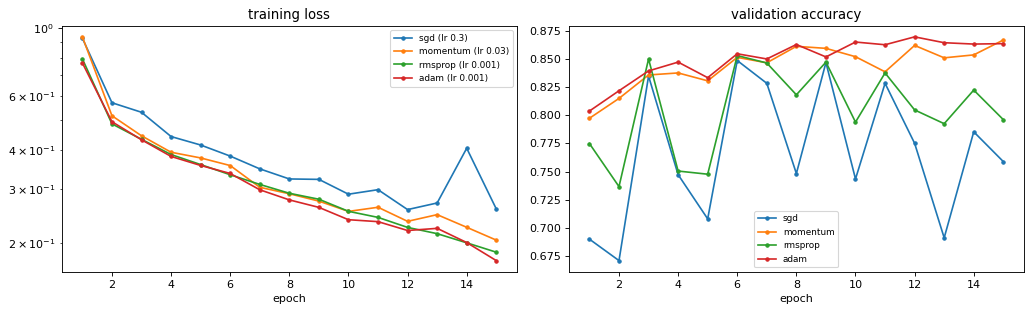

In [4]:
curves = {name: fit(make_mlp(hidden=(256, 128)), epochs=15, lr=lr, optimizer=name) for name, lr in best.items()}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h in curves.items():
    axes[0].plot(h.index, h["train loss"], marker="o", ms=3, label=f"{name} (lr {best[name]:g})")
    axes[1].plot(h.index, h["val acc"], marker="o", ms=3, label=name)
axes[0].set_yscale("log"); axes[0].set_title("training loss"); axes[1].set_title("validation accuracy")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**What we see.** At their own best learning rates, the four optimisers end up closer than their reputations suggest: best validation accuracy **84.8%** for plain SGD, **86.7%** for momentum, **85.3%** for RMSprop and **86.9%** for Adam. Two observations matter more than the ranking:
- The best rates differ by a factor of **300** (0.3 for SGD, 0.001 for Adam). Comparing optimisers at one shared rate measures the rate, not the optimiser. The best SGD rate sits at the edge of our grid, so SGD might do slightly better with an even larger rate; an honest sweep would extend the grid.
- The curves show **stability**. SGD at its high rate jumps from 67% to 85% and back from one epoch to the next, and RMSprop is also jumpy; momentum and Adam rise smoothly. Smooth curves make early stopping and model selection far more reliable.

Adam's advantage is not a much higher peak but that it works well across a **wide** range of rates with little tuning (85.0 to 86.9% from 0.0001 to 0.003), which is why it is the usual default.

## 4. Weight decay: Adam against AdamW

**Weight decay** pulls every weight slightly towards zero at each step, a form of regularisation (Notebook 09). In Adam, adding it to the gradient means it is also divided by the adaptive scale, so weights with large gradients are barely decayed. **AdamW** applies the decay **separately**, as intended.

In [5]:
wd_rows = {}
for name in ["adam", "adamw"]:
    for wd in [0.0, 1e-4, 1e-2, 1e-1]:
        h = fit(make_mlp(hidden=(1024,)), epochs=30, lr=1e-3, optimizer=name, weight_decay=wd)
        wd_rows.setdefault(name, {})[wd] = h["val acc"].iloc[-1]
pd.DataFrame(wd_rows).rename_axis("weight decay").round(4)

,adam,adamw
weight decay,,
0.000e+00,0.863,0.864
1.000e-04,0.849,0.869
1.000e-02,0.831,0.867
1.000e-01,0.783,0.861


**What we see.** With **Adam**, weight decay hurts steadily as it grows: 86.3% without it, **78.3%** at 0.1. Added to the gradient, the decay is divided by Adam's adaptive scale, so it acts unevenly and mostly disturbs training. With **AdamW**, the same values leave accuracy at **86.1 to 86.9%**: the decay is applied separately, at a size the learning rate controls. The small gain at 1e-4 (86.9% against 86.4%) is within seed noise, so we do not claim that decay helps this small problem; the clear result is that with AdamW the decay strength can be tuned **safely**, while with Adam it interferes. This is why AdamW is the standard optimiser for training Transformers.

## ⚠️ Common pitfalls

- **Comparing optimisers at one learning rate.** Each has its own good range; compare each at its best.
- **Using Adam's learning rate with SGD** (or the opposite): a factor of 10 to 100 off.
- **Weight decay with Adam instead of AdamW** when regularisation matters.
- **Assuming Adam always wins.** On some large image tasks, tuned SGD with momentum generalises slightly better; Adam is the safer default, not a guarantee.

## ✏️ Exercises

### Exercise 1 (Momentum values)
Train SGD with momentum 0, 0.5, 0.9 and 0.99 at learning rate 0.01 for 15 epochs. Which momentum works best? What goes wrong at 0.99?

In [6]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
for mom in [0.0, 0.5, 0.9, 0.99]:
    torch.manual_seed(0)
    m = make_mlp(hidden=(256, 128))
    opt = torch.optim.SGD(m.parameters(), lr=0.01, momentum=mom)
    for epoch in range(15):
        perm = torch.randperm(len(X_train))
        for i in range(0, len(X_train), 128):
            idx = perm[i:i + 128]
            loss = F.cross_entropy(m(X_train[idx]), y_train[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    print(f"momentum {mom}: val acc {accuracy(m, X_val, y_val):.4f}")
```

*In our run, validation accuracy rose from 80.6% without momentum to 83.2% at 0.5 and 85.5% at 0.9, then fell to 84.7% at 0.99: some momentum helps a lot, and 0.9 is the classic value for good reason. At 0.99 the velocity carries the weights past good regions unless the learning rate is lowered. Momentum and learning rate must be tuned together.*
</details>

### Exercise 2 (Adam's betas)
Adam has two more hyperparameters, `betas=(0.9, 0.999)`. Try `betas=(0.5, 0.999)` and `(0.9, 0.9)` with the best Adam learning rate. Does the default deserve its status?

In [7]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
for betas in [(0.9, 0.999), (0.5, 0.999), (0.9, 0.9)]:
    torch.manual_seed(0)
    m = make_mlp(hidden=(256, 128))
    opt = torch.optim.Adam(m.parameters(), lr=best["adam"], betas=betas)
    for epoch in range(15):
        perm = torch.randperm(len(X_train))
        for i in range(0, len(X_train), 128):
            idx = perm[i:i + 128]
            loss = F.cross_entropy(m(X_train[idx]), y_train[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    print(betas, round(accuracy(m, X_val, y_val), 4))
```

*Here the default (0.9, 0.999) gave 86.2%, (0.9, 0.9) 86.5% and (0.5, 0.999) 85.1%: differences of about a point. The defaults are close to best on most problems, which is part of why Adam is popular: it has hyperparameters, but rarely needs them changed. GANs (see Notebook 09 of From Papers to Practice) are a well-known exception, where beta1 = 0.5 is standard.*
</details>

## 🔑 Key takeaways

- **SGD** follows the gradient; **momentum** builds speed in consistent directions; **RMSprop** scales steps per weight; **Adam** combines both.
- Compare optimisers **each at its own best learning rate**.
- **Adam** (or **AdamW**) is the robust default; SGD with momentum remains competitive when carefully tuned.
- Use **AdamW** when you add weight decay.

---
**Next:** *Notebook 08: Weight Initialisation*, where training starts from.

---
*© Ioannis Tsioulis. *From Defaults to Decisions: Hyperparameters, Explained by Experiment*. Prepared for educational use.*